# Лабораторная работа № 2 — EDA временного ряда

**Цель:** исследовать временной ряд, пропуски и выбросы.  
**Данные:** [Individual Household Electric Power Consumption (UCI)](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption), 2007 год, средняя почасовая активная мощность (кВт).

## 1. Загрузка и проверка данных

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = (
    "https://archive.ics.uci.edu/static/public/235/"
    "individual+household+electric+power+consumption.zip"
)

df = pd.read_csv(
    url, compression="zip", sep=";",
    usecols=["Date", "Time", "Global_active_power"],
    na_values=["?"], low_memory=False,
)
df["timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S", errors="coerce",
)
df["Global_active_power"] = pd.to_numeric(df["Global_active_power"], errors="coerce")

invalid_dates = df["timestamp"].isna().sum()
duplicates = df["timestamp"].duplicated().sum()
df = (df.dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .drop_duplicates("timestamp")
        .set_index("timestamp"))

# Полная минутная сетка 2007 года и переход к часовым средним.
minute_index = pd.date_range("2007-01-01", "2007-12-31 23:59", freq="min")
minute_series = df.loc["2007", "Global_active_power"].reindex(minute_index)
series = minute_series.resample("h").mean().asfreq("h")

print(f"Некорректных дат: {invalid_dates}; дубликатов: {duplicates}")
print(f"Пропусков в минутных данных: {minute_series.isna().sum()}")
print(f"Часовой ряд: {len(series)} наблюдений, {series.isna().sum()} пропусков")

Некорректных дат: 0; дубликатов: 0
Пропусков в минутных данных: 3931
Часовой ряд: 8760 наблюдений, 62 пропусков


## 2. Графики и скользящие статистики

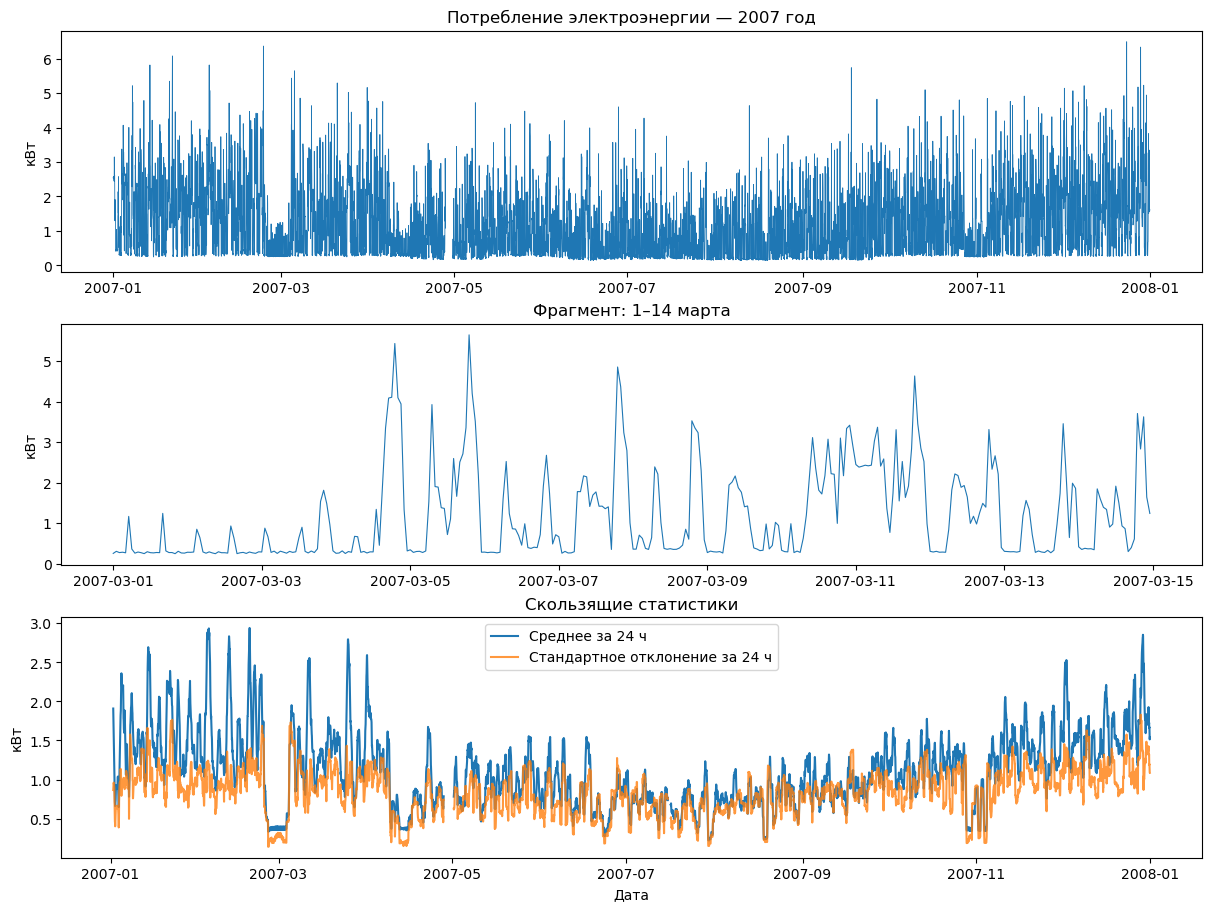

In [9]:
rolling_mean = series.rolling(24).mean()
rolling_std = series.rolling(24).std()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
axes[0].plot(series, lw=0.6)
axes[0].set(title="Потребление электроэнергии — 2007 год", ylabel="кВт")

axes[1].plot(series.loc["2007-03-01":"2007-03-14"], lw=0.8)
axes[1].set(title="Фрагмент: 1–14 марта", ylabel="кВт")

axes[2].plot(rolling_mean, label="Среднее за 24 ч")
axes[2].plot(rolling_std, label="Стандартное отклонение за 24 ч", alpha=0.8)
axes[2].set(title="Скользящие статистики", xlabel="Дата", ylabel="кВт")
axes[2].legend()
plt.show()

## 3. Сезонность

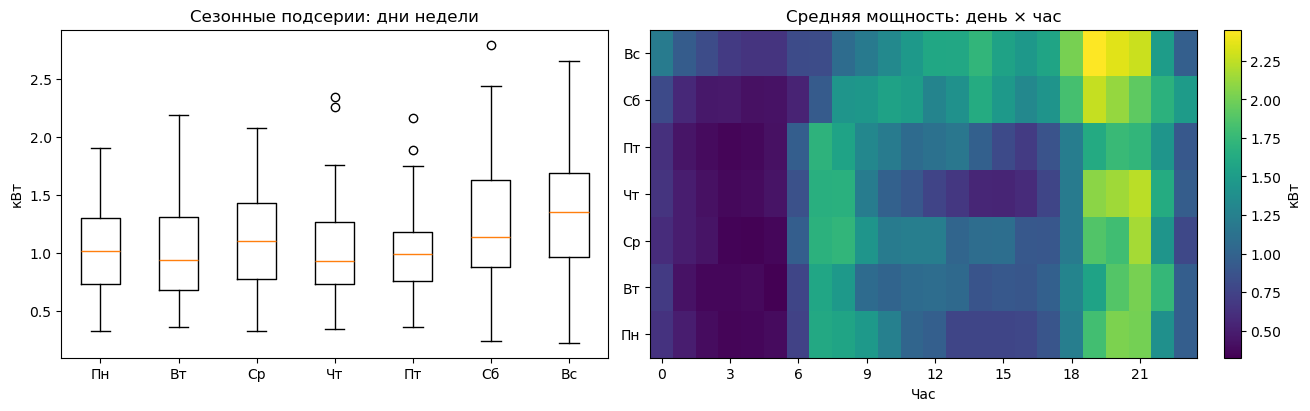

In [10]:
# Подсерии по дням недели и тепловая карта «день недели × час».
daily = series.resample("D").mean()
weekday_names = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
weekday_data = [daily[daily.index.dayofweek == i].dropna().values for i in range(7)]

heatmap = (series.groupby([series.index.dayofweek, series.index.hour])
           .mean().unstack().reindex(index=range(7), columns=range(24)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
axes[0].boxplot(weekday_data)
axes[0].set(xticks=range(1, 8), xticklabels=weekday_names,
            title="Сезонные подсерии: дни недели", ylabel="кВт")

im = axes[1].imshow(heatmap, aspect="auto", origin="lower", cmap="viridis")
axes[1].set(yticks=range(7), yticklabels=weekday_names,
            xticks=range(0, 24, 3), title="Средняя мощность: день × час", xlabel="Час")
fig.colorbar(im, ax=axes[1], label="кВт")
plt.show()

## 4. Анализ пропусков

 Часов с пропусками  Доля, %  Макс. серия, ч
                 62     0.71              61


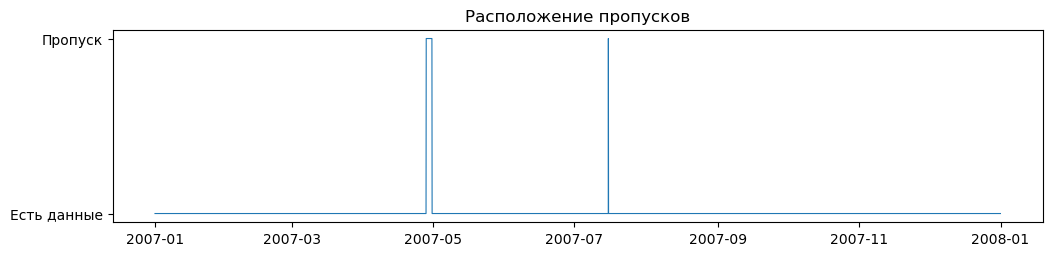

In [11]:
missing = series.isna()
groups = missing.ne(missing.shift(fill_value=False)).cumsum()
missing_runs = missing.groupby(groups).sum()
longest_gap = int(missing_runs.max()) if len(missing_runs) else 0

missing_summary = pd.DataFrame({
    "Часов с пропусками": [int(missing.sum())],
    "Доля, %": [round(100 * missing.mean(), 2)],
    "Макс. серия, ч": [longest_gap],
})
print(missing_summary.to_string(index=False))

plt.figure(figsize=(12, 2.5))
plt.plot(missing.index, missing.astype(int), lw=0.8)
plt.yticks([0, 1], ["Есть данные", "Пропуск"])
plt.title("Расположение пропусков")
plt.show()

## 5. Сравнение двух методов заполнения пропусков

FFill     0.462
Linear    0.371


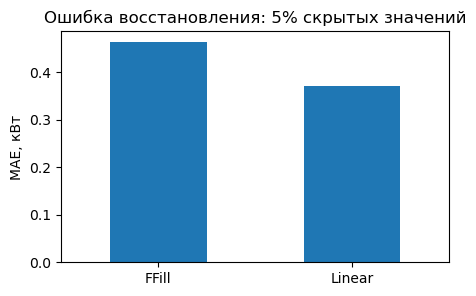

In [12]:
# Скрываем 5% известных значений и сравниваем FFill с линейной интерполяцией.
rng = np.random.default_rng(42)
known = np.flatnonzero(series.notna().to_numpy())
check_positions = rng.choice(known[1:-1], size=int(0.05 * len(known)), replace=False)
check_index = series.index[check_positions]

masked = series.copy()
masked.iloc[check_positions] = np.nan

ffill = masked.ffill()
linear = masked.interpolate(method="time", limit_direction="both")

errors = pd.Series({
    "FFill": (ffill.loc[check_index] - series.loc[check_index]).abs().mean(),
    "Linear": (linear.loc[check_index] - series.loc[check_index]).abs().mean(),
}, name="MAE, кВт")
print(errors.round(3).to_string())

plt.figure(figsize=(5, 3))
errors.plot.bar(rot=0)
plt.ylabel("MAE, кВт")
plt.title("Ошибка восстановления: 5% скрытых значений")
plt.show()

## 6. Поиск выбросов: IQR, z-score и rolling MAD

Найденные выбросы:
IQR            192
Z-score        105
Rolling MAD    557

Примеры выбросов:
                     power_kw   IQR  Z-score  Rolling MAD
2007-01-04 12:00:00     4.067  True    False        False
2007-01-06 12:00:00     4.003  True    False        False
2007-01-07 15:00:00     3.771  True    False        False
2007-01-07 18:00:00     5.212  True     True        False
2007-01-07 21:00:00     4.738  True     True        False


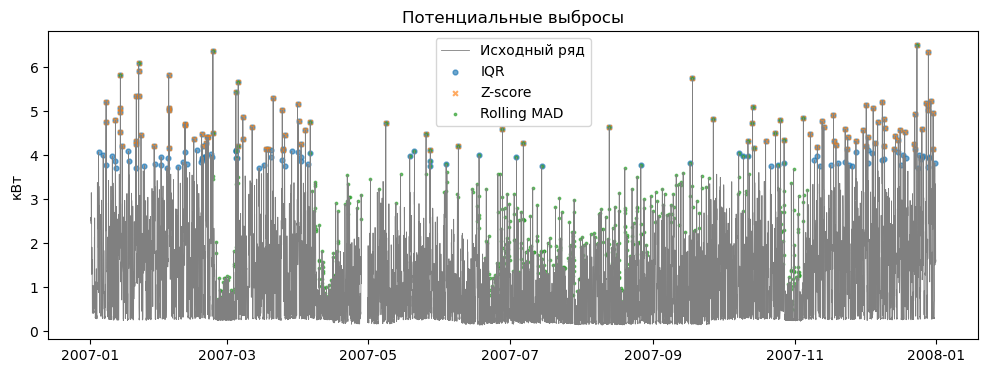

In [13]:
observed = series.dropna()

q1, q3 = observed.quantile([0.25, 0.75])
iqr = q3 - q1
out_iqr = (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

z = (series - observed.mean()) / observed.std(ddof=0)
out_z = z.abs() > 3

local_median = series.rolling(168, center=True, min_periods=24).median()
residual = (series - local_median).abs()
mad = residual.rolling(168, center=True, min_periods=24).median()
out_mad = 0.6745 * residual / mad.replace(0, np.nan) > 3.5

flags = pd.DataFrame({"IQR": out_iqr, "Z-score": out_z, "Rolling MAD": out_mad})
print("Найденные выбросы:")
print(flags.sum().to_string())

# Первые найденные наблюдения с отметками методов.
outlier_table = pd.concat([series.rename("power_kw"), flags], axis=1)
print("\nПримеры выбросов:")
print(outlier_table.loc[flags.any(axis=1)].head(5).round(3).to_string())

plt.figure(figsize=(12, 4))
plt.plot(series, lw=0.6, color="gray", label="Исходный ряд")
for name, marker in [("IQR", "o"), ("Z-score", "x"), ("Rolling MAD", ".")]:
    selected = series[flags[name]]
    plt.scatter(selected.index, selected.values, s=12, marker=marker, label=name, alpha=0.65)
plt.title("Потенциальные выбросы")
plt.ylabel("кВт")
plt.legend()
plt.show()

## 7. Выводы

По результатам графиков и расчётов проверяем регулярность данных, сезонные закономерности, точность заполнения пропусков и найденные аномалии.

In [14]:
quarter_mean = series.resample("Q").mean()
peak_hour = int(series.groupby(series.index.hour).mean().idxmax())

print(f"1. Пропуски: {missing.sum()} ч ({100 * missing.mean():.2f}%), самая длинная серия — {longest_gap} ч.")
print(f"2. Наибольшее среднее потребление наблюдается около {peak_hour}:00; видны суточные и недельные различия.")
print(f"3. Средняя мощность в I и IV кварталах: {quarter_mean.iloc[0]:.2f} и {quarter_mean.iloc[-1]:.2f} кВт.")
print(f"4. Меньшую ошибку на скрытых значениях дал метод {errors.idxmin()} (MAE = {errors.min():.3f} кВт).")
print("5. Выбросы — возможные пики потребления, а не обязательно ошибки; нужна проверка контекста." if flags.any().any()
      else "5. Выбросов по выбранным порогам не выявлено; отсутствие флагов не гарантирует отсутствие аномалий.")

1. Пропуски: 62 ч (0.71%), самая длинная серия — 61 ч.
2. Наибольшее среднее потребление наблюдается около 21:00; видны суточные и недельные различия.
3. Средняя мощность в I и IV кварталах: 1.42 и 1.34 кВт.
4. Меньшую ошибку на скрытых значениях дал метод Linear (MAE = 0.371 кВт).
5. Выбросы — возможные пики потребления, а не обязательно ошибки; нужна проверка контекста.
